# Experiment 5.2: Musical Effects Using a Time-Varying Delay

This experiment compares a fixed-delay echo with a periodically changing delay on a stereo recording. It also compares waveforms and magnitude spectra with the original signal.

Input: stereo signed 16-bit `mixture.wav`. Both experiments process only seconds 20–30 (10 seconds). Plot time zero refers to 20 seconds in the original recording. Place the WAV beside this notebook.

Input: stereo signed 16-bit `mixture.wav`. Both experiments process only seconds 20–30 (10 seconds). Plot time zero refers to 20 seconds in the original recording. Place the WAV beside this notebook.

## Interactive zoom setup
Run the install cell once, then restart the kernel and run from the widget cell onward. Use the magnifying glass on each plot toolbar and drag a rectangle to zoom; Home resets the view. PNG exports remain static. Your notebook viewer must support Jupyter widgets.

In [10]:
%pip install ipympl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\tejas\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [11]:
%matplotlib widget

In [12]:
from pathlib import Path
import cmath
import math
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import wavfile

script_dir = Path.cwd()
project_dir = script_dir.parent if script_dir.name.lower() == 'source code' else script_dir
output_dir = script_dir / 'outputs'
output_dir.mkdir(exist_ok=True)
plot_dir = project_dir / 'plots'
plot_dir.mkdir(exist_ok=True)
input_path = script_dir / 'mixture.wav'
fs, original = wavfile.read(input_path)
# mixture.wav is signed 16-bit PCM: map its sample values to [-1, 1).
if original.dtype != np.int16:
    raise ValueError('Expected signed 16-bit PCM for division by 32768.0.')
audio = original.astype(float) / 32768.0
start = 20 * fs
end = 30 * fs
if len(audio) < end:
    raise ValueError('The input must contain at least 30 seconds.')
audio_selected = audio[start:end]
audio = audio_selected.copy()
sample_rate = fs
if audio.ndim != 2 or audio.shape[1] != 2:
    raise ValueError('Expected two-channel stereo audio.')
num_samples, num_channels = audio.shape


FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\tejas\\Downloads\\lssp-midterm-final\\source code\\mixture.wav'

## Delay model and settings

The delay is $D(n)=D_0+\Delta D\sin(2\pi f_m n/f_s)$. To make the effect more prominent, use nominal delay 20 ms, variation 15 ms (delay range 5–35 ms), modulation frequency 4 Hz, and echo gain 0.9. Use matching nominal delay and gain in the fixed baseline. These demonstration settings replace the earlier 5 ms, 1 Hz, 0.5 settings.

In [ ]:
# Echo settings.
alpha = 0.9
D0_seconds = 0.020        # Nominal delay: 20 ms
delta_D_seconds = 0.015   # Delay varies by +/- 15 ms
fm = 4.0                  # Modulation frequency: 4 Hz

D0 = round(D0_seconds * sample_rate)
delta_D = round(delta_D_seconds * sample_rate)

n = np.arange(num_samples)

# Fixed-delay echo, for comparison.
fixed = audio.copy()
if D0 < num_samples:
    fixed[D0:] += alpha * audio[:-D0]

# Time-varying delay: D(n) = D0 + delta_D * sin(2*pi*fm*n/fs).
variable_delays = np.rint(
    D0 + delta_D * np.sin(2 * np.pi * fm * n / sample_rate)
).astype(int)

time_varying = audio.copy()
source_indices = n - variable_delays
valid = source_indices >= 0

# Apply the variable delay independently to the left and right channels.
for channel in range(num_channels):
    time_varying[valid, channel] += (
        alpha * audio[source_indices[valid], channel]
    )




## Save and listen to the outputs

The generated stereo WAV files are written to the project `outputs` folder. Run this cell before comparing the plots.

In [ ]:
# Save the stereo output as a floating-point WAV file.
def save_float_wav(path, signal):
    peak = np.max(np.abs(signal))
    if peak > 1:
        signal = signal / peak
    wavfile.write(path, sample_rate, signal.astype(np.float32))


fixed_path = output_dir / "fixed_delay_echo_5_2.wav"
variable_path = output_dir / "time_varying_echo_5_2.wav"

save_float_wav(fixed_path, fixed)
save_float_wav(variable_path, time_varying)

print(f"Saved fixed-delay echo: {fixed_path}")
print(f"Saved time-varying echo: {variable_path}")



Saved fixed-delay echo: c:\Users\tejas\Downloads\lssp-midterm-final\source code\outputs\fixed_delay_echo_5_2.wav
Saved time-varying echo: c:\Users\tejas\Downloads\lssp-midterm-final\source code\outputs\time_varying_echo_5_2.wav


## Waveform comparison

The first 0.1 seconds provide an overview. The parameter study also shows a short detail window and the difference from the fixed-delay output, which avoid dense overlapping traces hiding the effect.

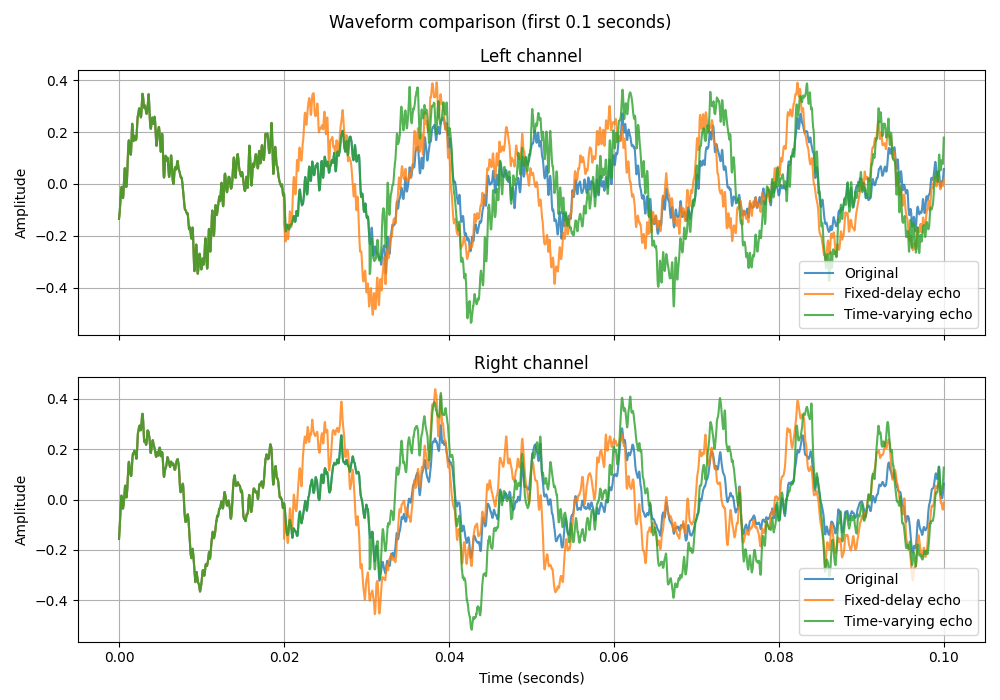

In [ ]:
# Plot the first 0.1 seconds for the left and right channels.
view_samples = min(num_samples, int(0.1 * sample_rate))
time = np.arange(view_samples) / sample_rate

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for channel, axis in enumerate(axes):
    channel_name = "Left" if channel == 0 else "Right"
    axis.plot(time, audio[:view_samples, channel], label="Original", alpha=0.8)
    axis.plot(time, fixed[:view_samples, channel], label="Fixed-delay echo", alpha=0.8)
    axis.plot(time, time_varying[:view_samples, channel], label="Time-varying echo", alpha=0.8)
    axis.set_ylabel("Amplitude")
    axis.set_title(f"{channel_name} channel")
    axis.legend()
    axis.grid(True)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Waveform comparison (first 0.1 seconds)")
fig.tight_layout()
fig.savefig(plot_dir / "5.2_waveform_comparison.png", dpi=150)
plt.show()


## Manual FFT and magnitude helper

A recursive radix-2 Cooley-Tukey FFT calculates the spectra without calling a signal-processing FFT library.

In [ ]:
def fft(signal):
    """Compute the DFT recursively with the radix-2 Cooley-Tukey algorithm.

    The input is zero-padded to the next power of two before splitting.
    """
    N = len(signal)
    if N == 0:
        return []
    if N <= 1:
        return signal

    # Pad once, at the top level, so recursive halves stay powers of two.
    if N & (N - 1):
        next_pow2 = 1 << (N - 1).bit_length()
        signal = list(signal) + [0] * (next_pow2 - N)
        N = next_pow2

    even = fft(signal[0::2])
    odd = fft(signal[1::2])

    combined = [0] * N
    for k in range(N // 2):
        twiddle = cmath.exp(-2j * cmath.pi * k / N)
        combined[k] = even[k] + twiddle * odd[k]
        combined[k + N // 2] = even[k] - twiddle * odd[k]

    return combined

# Compare spectra from the first five seconds for both channels.
segment_samples = min(num_samples, int(5 * sample_rate))


def magnitude_spectrum(signal, channel):
    segment = signal[:segment_samples, channel]
    spectrum = fft(segment)
    fft_length = len(spectrum)
    positive_length = fft_length // 2 + 1

    frequencies = [
        k * sample_rate / fft_length
        for k in range(positive_length)
    ]
    magnitude_db = [
        20 * math.log10(max(abs(spectrum[k]), 1e-10))
        for k in range(positive_length)
    ]
    return frequencies, magnitude_db




## Magnitude spectra

The next plot compares the original, fixed-delay, and time-varying signals over the first five seconds for the left and right channels. The figure is also saved in `outputs`.

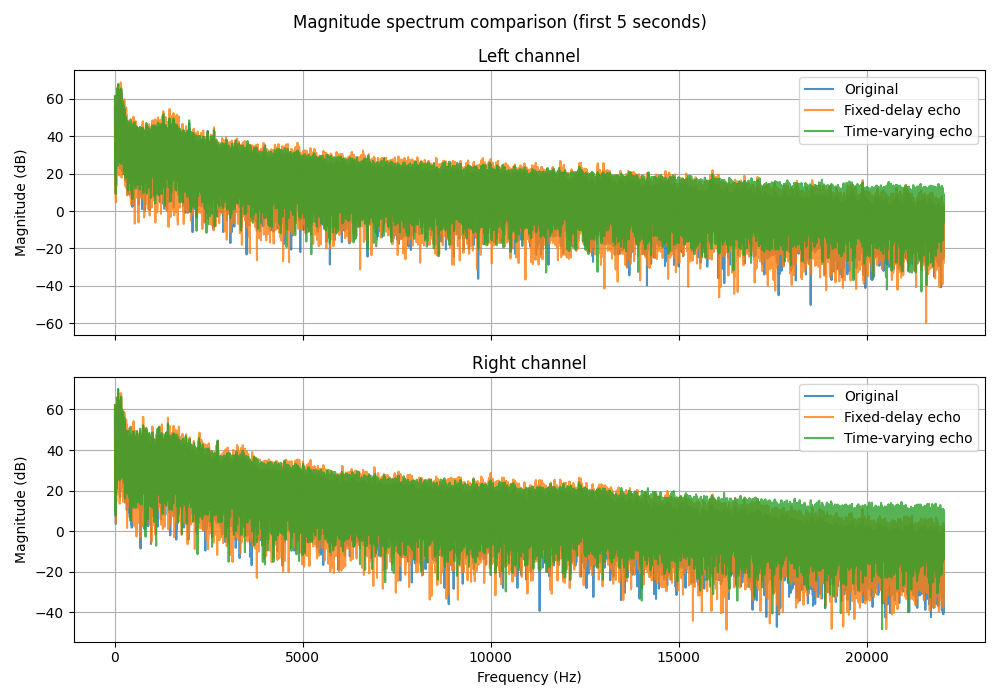

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for channel, axis in enumerate(axes):
    channel_name = "Left" if channel == 0 else "Right"
    f_original, mag_original = magnitude_spectrum(audio, channel)
    f_fixed, mag_fixed = magnitude_spectrum(fixed, channel)
    f_variable, mag_variable = magnitude_spectrum(time_varying, channel)

    axis.plot(f_original, mag_original, label="Original", alpha=0.8)
    axis.plot(f_fixed, mag_fixed, label="Fixed-delay echo", alpha=0.8)
    axis.plot(f_variable, mag_variable, label="Time-varying echo", alpha=0.8)
    axis.set_ylabel("Magnitude (dB)")
    axis.set_title(f"{channel_name} channel")
    axis.legend()
    axis.grid(True)

axes[-1].set_xlabel("Frequency (Hz)")
fig.suptitle("Magnitude spectrum comparison (first 5 seconds)")
fig.tight_layout()
fig.savefig(plot_dir / "5.2_magnitude_spectra.png", dpi=150)
plt.show()

## Stronger parameter study

Nominal delay stays at 20 ms and echo gain at 0.9 for both fixed and variable outputs. Compare modulation rates 0.5, 4 and 10 Hz at 15 ms depth, then depths 0, 5, 15 and 19 ms at 4 Hz (six unique cases). Depth 19 ms gives a 1–39 ms delay range. The 4 Hz, 15 ms case is shared. Higher rates and depths make the effect stronger; they may sound exaggerated. Detail plots show 20 ms near 0.5 seconds where possible. Difference plots show variable minus fixed over the entire recording. All curves retain their real amplitudes. Repeat with each recording and enter the actual Experiment 1 baseline settings if required.

Original


Fixed delay


fm_0.5Hz_depth_15ms


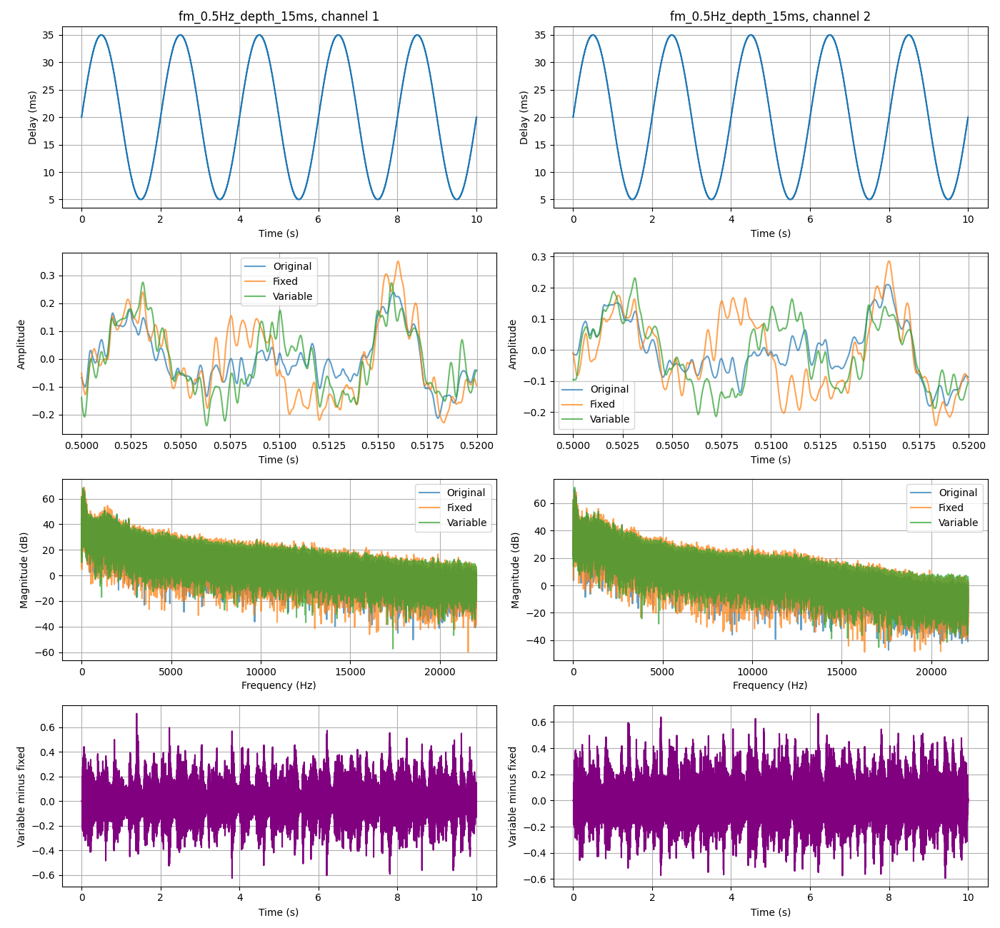

fm_4Hz_depth_15ms


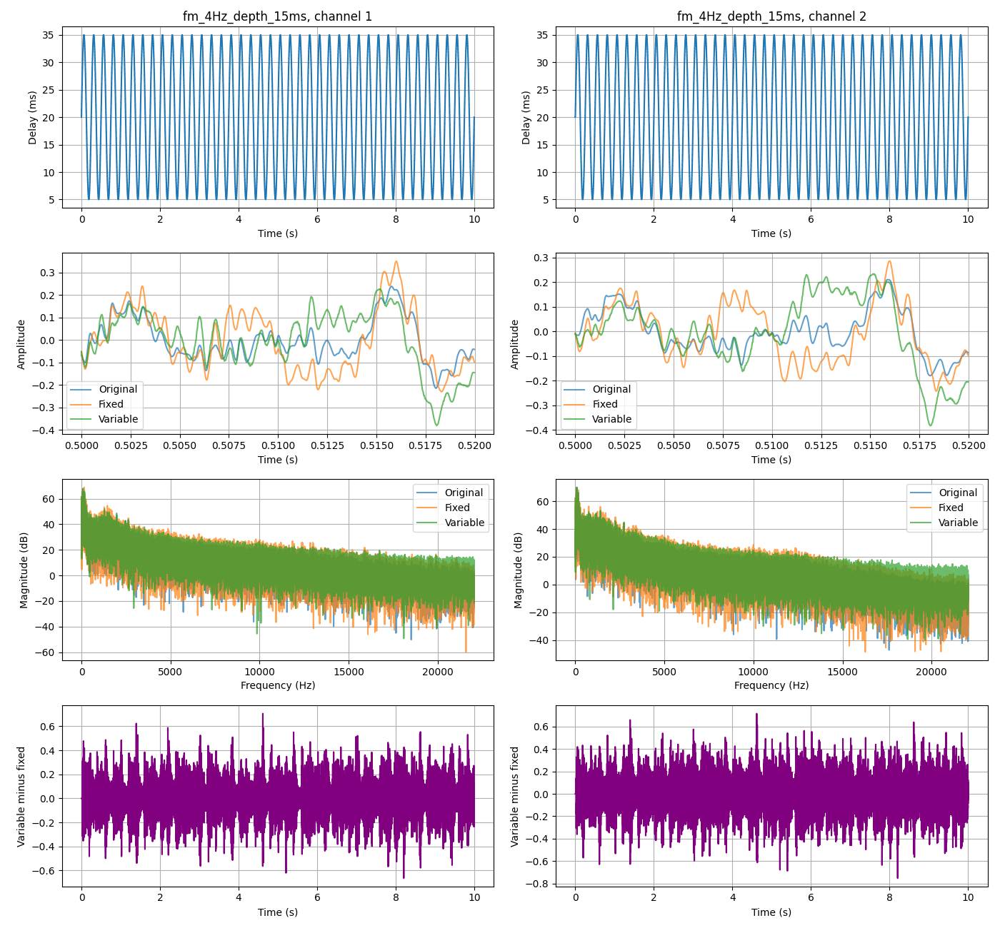

fm_10Hz_depth_15ms


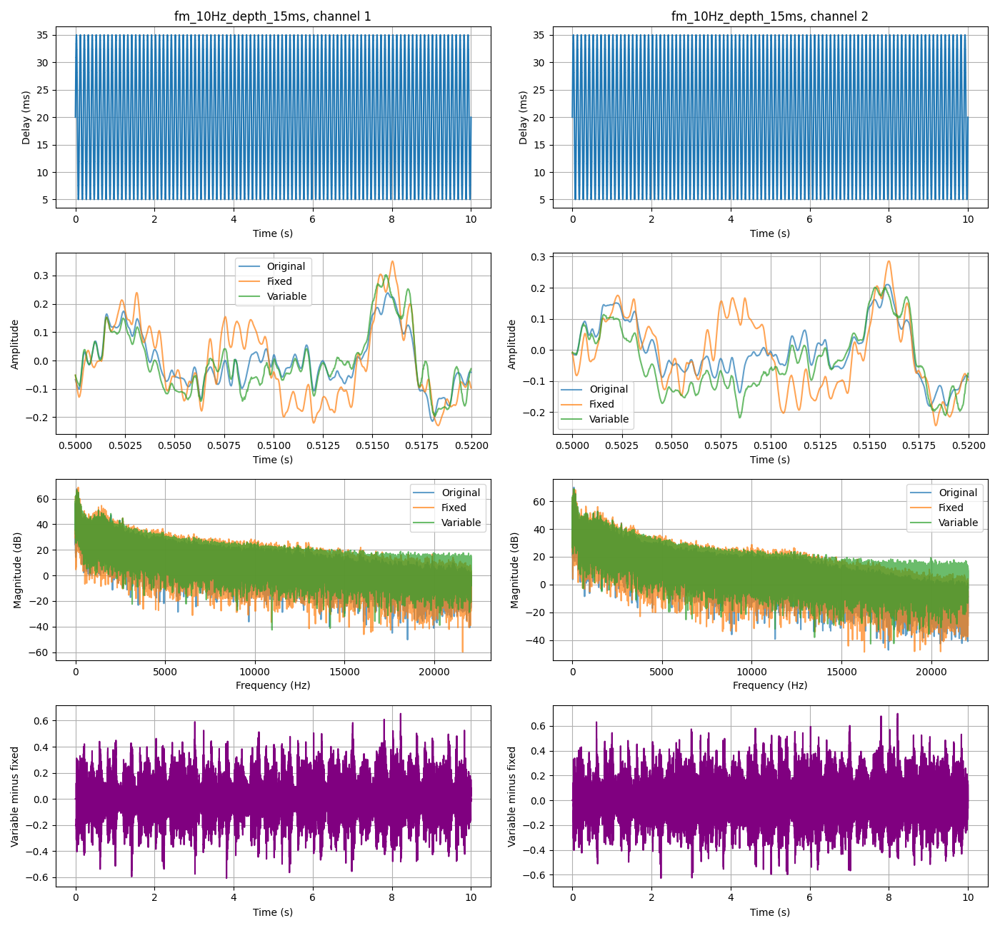

fm_4Hz_depth_0ms


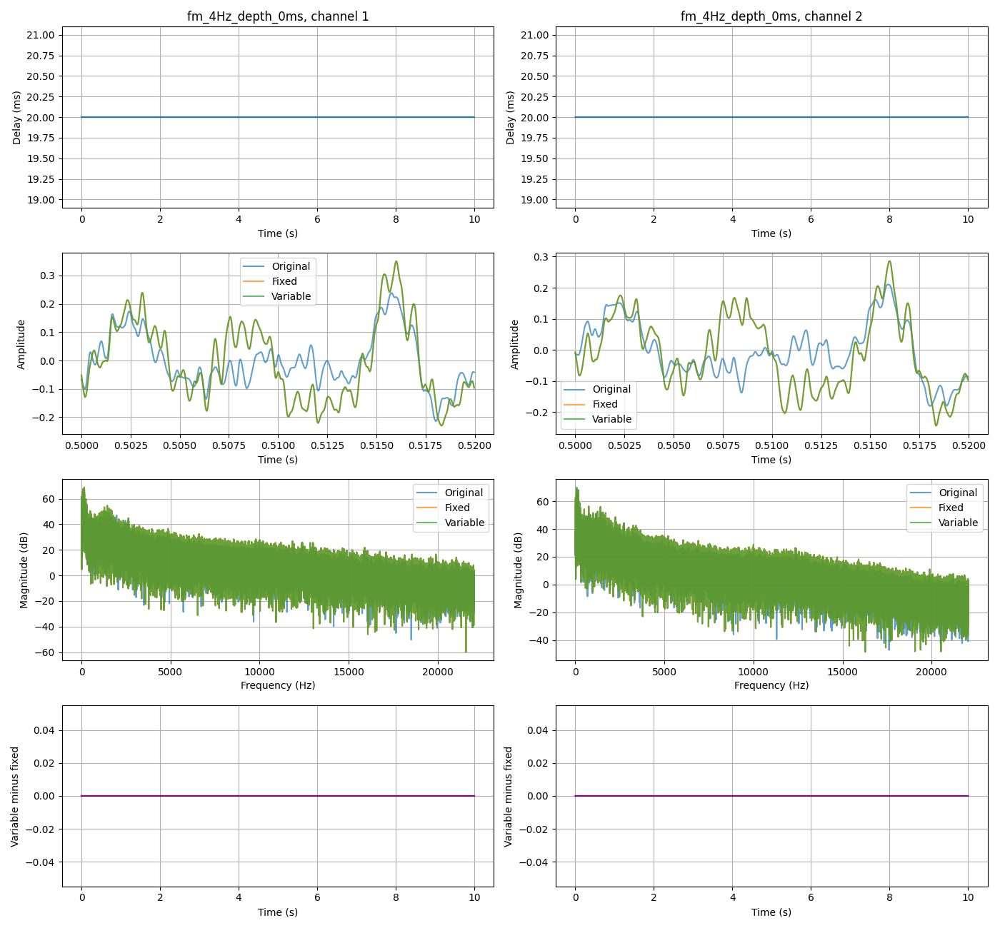

fm_4Hz_depth_5ms


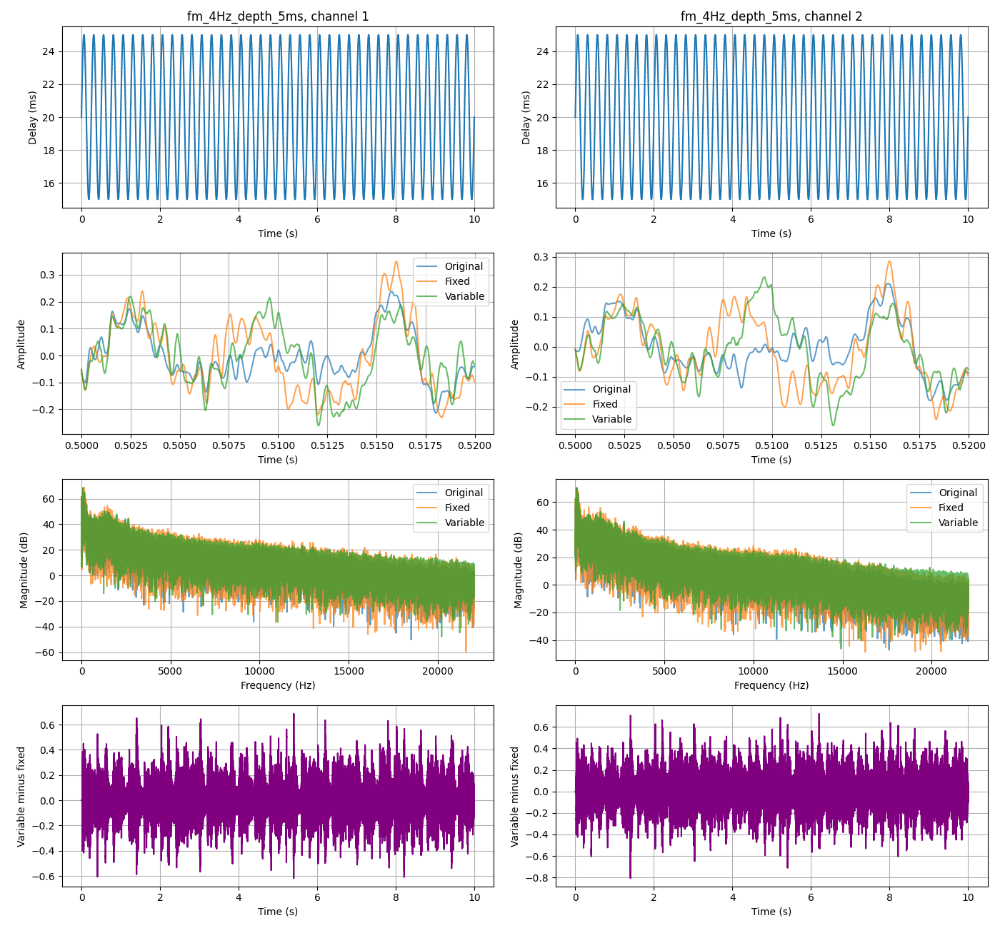

fm_4Hz_depth_19ms


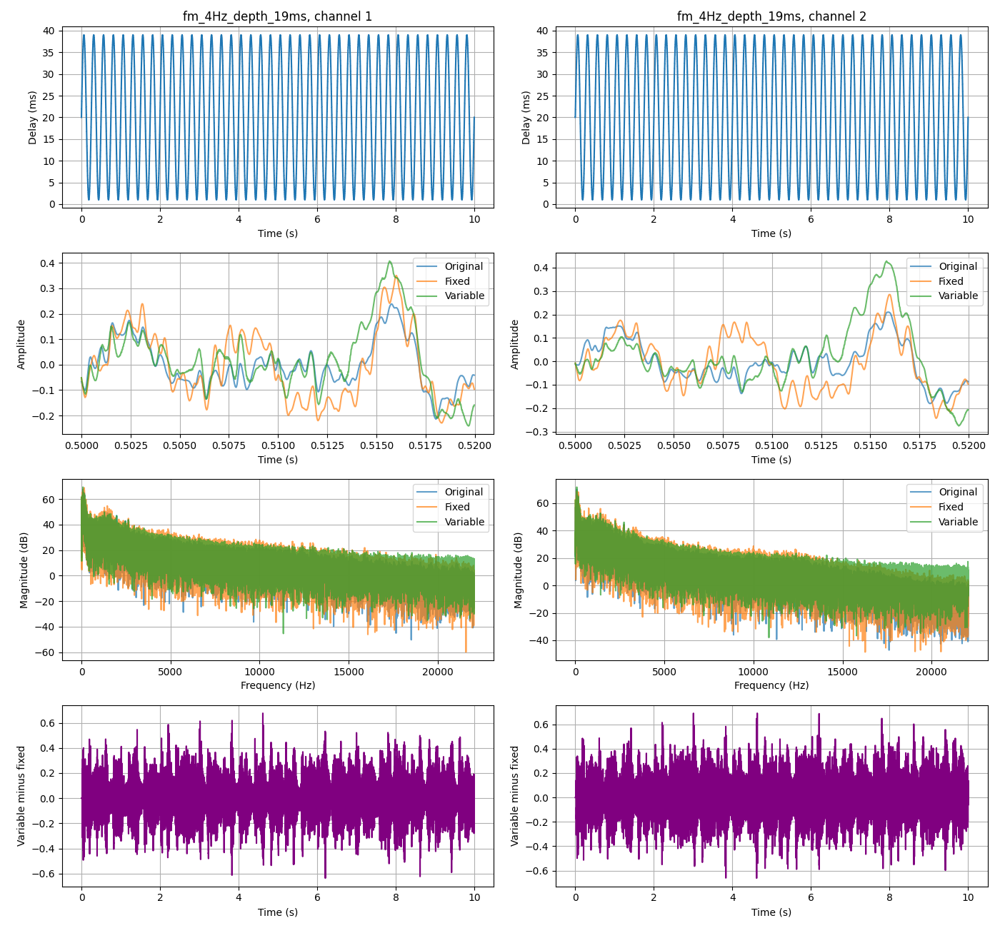

In [ ]:
from IPython.display import Audio, display

def variable_echo(x, fs, nominal, depth, rate, gain):
    if not (nominal >= depth >= 0 and rate >= 0):
        raise ValueError('Require nominal >= depth >= 0 and rate >= 0')
    n = np.arange(len(x))
    delays = np.rint(fs*(nominal + depth*np.sin(2*np.pi*rate*n/fs))).astype(int)
    source = n-delays
    valid = (source >= 0) & (source < len(x))
    y = x.copy()
    y[valid] += gain*x[source[valid]]
    return y, delays

np.testing.assert_allclose(variable_echo(audio, sample_rate, D0_seconds, 0, fm, alpha)[0], fixed, atol=1e-6)
settings = [(r, .015) for r in (.5, 4., 10.)] + [(4., d) for d in (0., .005, .019)]
# A shared gain preserves relative levels and avoids playback clipping.
gain = 1/(max(1., float(np.max(np.abs(audio))))*(1+abs(alpha)))
for name, signal in [('Original', audio), ('Fixed delay', fixed)]:
    print(name)
    display(Audio((signal*gain).T, rate=sample_rate, normalize=False))
for rate, depth in settings:
    label = f'fm_{rate:g}Hz_depth_{depth*1000:g}ms'
    y, delays = variable_echo(audio, sample_rate, D0_seconds, depth, rate, alpha)
    wavfile.write(output_dir / f'{label}.wav', sample_rate, (y*gain).astype(np.float32))
    print(label)
    display(Audio((y*gain).T, rate=sample_rate, normalize=False))
    fig, axes = plt.subplots(4, 2, figsize=(14, 13))
    for ch in range(2):
        axes[0,ch].plot(np.arange(num_samples)/sample_rate, delays/sample_rate*1000)
        axes[0,ch].set(title=f'{label}, channel {ch+1}', xlabel='Time (s)', ylabel='Delay (ms)')
        for name, signal in [('Original',audio), ('Fixed',fixed), ('Variable',y)]:
            start = min(int(.5*sample_rate), max(0, num_samples-int(.02*sample_rate)))
            stop = min(num_samples, start+max(2, int(.02*sample_rate)))
            detail_t = np.arange(start,stop)/sample_rate
            axes[1,ch].plot(detail_t, signal[start:stop,ch], label=name, alpha=.7)
            f, mag = magnitude_spectrum(signal,ch)
            axes[2,ch].plot(f,mag,label=name,alpha=.7)
        axes[1,ch].set(xlabel='Time (s)',ylabel='Amplitude')
        axes[2,ch].set(xlabel='Frequency (Hz)',ylabel='Magnitude (dB)')
        for row in (1,2):
            axes[row,ch].legend()
        axes[3,ch].plot(np.arange(num_samples)/sample_rate, y[:,ch]-fixed[:,ch], color='purple')
        axes[3,ch].set(xlabel='Time (s)', ylabel='Variable minus fixed')
        for row in range(4):
            axes[row,ch].grid(True)
    fig.tight_layout()
    fig.savefig(plot_dir / f'5.2_{label}_comparison.png',dpi=150)
    plt.show()
    # Keep the figure open so its interactive zoom toolbar remains usable.

## Discussion and task coverage
1. Time-varying delay is implemented using the stated sinusoidal equation, independently for both channels.
2. Fixed-delay comparison appears in the original plots and every parameter-study figure; players support listening comparisons.
3. Modulation rates 0.5, 4 and 10 Hz are compared at 15 ms depth. Depths 0, 5, 15 and 19 ms are compared at 4 Hz. Zero depth is checked against the fixed echo.
4. Each case processes the recording, exports a WAV, and compares stereo waveforms and magnitude spectra with the original. Repeat for each required recording.

Expected behavior: fixed delay creates stationary comb filtering; changing delay moves the interference pattern. Higher modulation frequency speeds up the movement. Larger depth widens the delay excursion and generally increases pitch movement. Zero depth is the fixed-delay limit. These are theoretical expectations, not claimed measured or listening results.

After running, record each input filename, audible changes across settings, waveform differences and observed spectral changes. Spectra use the same first-five-second segment and DFT scale. A whole-segment spectrum does not show when moving notches occur. The short waveform view shows local changes; the full-duration delay curve shows the modulation. Short recordings may not cover a complete slow cycle.